# Car Price Prediction Using Linear Regression

## Project Report Submitted By

**Name:** Pratibha Hebballi

**Branch:** CSE (AI)

**Semester:** 3rd Semester

**College:** KLE Technological University

---

## Program Details

**Program:** Unlox Artificial Intelligence Program

**Mentor:** Sruthi Tarimana

---
**Dataset Link:** https://www.kaggle.com/nehalbirla/motorcycle-dataset
## Project Information

**Project Title:** Car Price Prediction Using Linear Regression

**Dataset:** Car Details From Car Dekho Dataset

**Dataset Source:** Kaggle

---

## Project Objective

The objective of this project is to analyze the Car Dekho dataset and build a Linear Regression model to predict car selling prices. The project includes data cleaning, exploratory data analysis (EDA), outlier detection, feature encoding, data visualization, model training, and performance evaluation. By studying factors such as manufacturing year, kilometers driven, fuel type, transmission type, seller type, and ownership history, the project aims to identify the key factors affecting car prices and develop a predictive model.

## Dataset Description

The dataset contains information about used cars listed on Car Dekho. It includes details such as car name, manufacturing year, selling price, kilometers driven, fuel type, seller type, transmission type, and ownership history.

### Dataset Size

- Rows: 4340
- Columns: 8

## Expected Outcome

The Linear Regression model will learn the relationship between car features and selling price. Using the trained model, it will be possible to estimate the selling price of a car based on its characteristics. The project also provides valuable insights into trends and patterns present in the used car market through data visualization and statistical analysis.

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [4]:
df = pd.read_csv("/content/CAR DETAILS FROM CAR DEKHO.csv")

In [5]:
df.head()

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner
0,Maruti 800 AC,2007,60000,70000,Petrol,Individual,Manual,First Owner
1,Maruti Wagon R LXI Minor,2007,135000,50000,Petrol,Individual,Manual,First Owner
2,Hyundai Verna 1.6 SX,2012,600000,100000,Diesel,Individual,Manual,First Owner
3,Datsun RediGO T Option,2017,250000,46000,Petrol,Individual,Manual,First Owner
4,Honda Amaze VX i-DTEC,2014,450000,141000,Diesel,Individual,Manual,Second Owner


In [6]:
df.tail()

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner
4335,Hyundai i20 Magna 1.4 CRDi (Diesel),2014,409999,80000,Diesel,Individual,Manual,Second Owner
4336,Hyundai i20 Magna 1.4 CRDi,2014,409999,80000,Diesel,Individual,Manual,Second Owner
4337,Maruti 800 AC BSIII,2009,110000,83000,Petrol,Individual,Manual,Second Owner
4338,Hyundai Creta 1.6 CRDi SX Option,2016,865000,90000,Diesel,Individual,Manual,First Owner
4339,Renault KWID RXT,2016,225000,40000,Petrol,Individual,Manual,First Owner


In [7]:
df.shape

(4340, 8)

In [8]:
df.columns

Index(['name', 'year', 'selling_price', 'km_driven', 'fuel', 'seller_type',
       'transmission', 'owner'],
      dtype='object')

In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4340 entries, 0 to 4339
Data columns (total 8 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   name           4340 non-null   object
 1   year           4340 non-null   int64 
 2   selling_price  4340 non-null   int64 
 3   km_driven      4340 non-null   int64 
 4   fuel           4340 non-null   object
 5   seller_type    4340 non-null   object
 6   transmission   4340 non-null   object
 7   owner          4340 non-null   object
dtypes: int64(3), object(5)
memory usage: 271.4+ KB


In [10]:
df.describe()

,year,selling_price,km_driven
count,4340.000000,4.340000e+03,4340.000000
mean,2013.090783,5.041273e+05,66215.777419
std,4.215344,5.785487e+05,46644.102194
min,1992.000000,2.000000e+04,1.000000
25%,2011.000000,2.087498e+05,35000.000000
50%,2014.000000,3.500000e+05,60000.000000
75%,2016.000000,6.000000e+05,90000.000000
max,2020.000000,8.900000e+06,806599.000000


In [11]:
df.isnull().sum()



,0
name,0
year,0
selling_price,0
km_driven,0
fuel,0
seller_type,0
transmission,0
owner,0


In [12]:
df.duplicated().sum()

np.int64(763)

In [18]:
df_clean = df.copy()

df_clean.drop_duplicates(inplace=True)

In [19]:
df_clean.shape

(3577, 8)

In [20]:
numeric_cols = df_clean.select_dtypes(include='number')

In [21]:
numeric_cols.columns

Index(['year', 'selling_price', 'km_driven'], dtype='object')

In [22]:
df.head()

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner
0,Maruti 800 AC,2007,60000,70000,Petrol,Individual,Manual,First Owner
1,Maruti Wagon R LXI Minor,2007,135000,50000,Petrol,Individual,Manual,First Owner
2,Hyundai Verna 1.6 SX,2012,600000,100000,Diesel,Individual,Manual,First Owner
3,Datsun RediGO T Option,2017,250000,46000,Petrol,Individual,Manual,First Owner
4,Honda Amaze VX i-DTEC,2014,450000,141000,Diesel,Individual,Manual,Second Owner


In [23]:
numeric_cols = df_clean.select_dtypes(include='number')

numeric_cols.columns

Index(['year', 'selling_price', 'km_driven'], dtype='object')

In [24]:
categorical_cols = df_clean.select_dtypes(include='object')

categorical_cols.columns

Index(['name', 'fuel', 'seller_type', 'transmission', 'owner'], dtype='object')

In [25]:
df_clean['name'].value_counts().head(10)

,count
name,
Maruti Swift Dzire VDI,54
Maruti Alto 800 LXI,48
Maruti Alto LXi,42
Maruti Alto LX,30
Maruti Swift VDI BSIV,28
Hyundai EON Era Plus,28
Maruti Wagon R VXI BS IV,26
Maruti Swift VDI,23
Maruti Wagon R LXI Minor,21


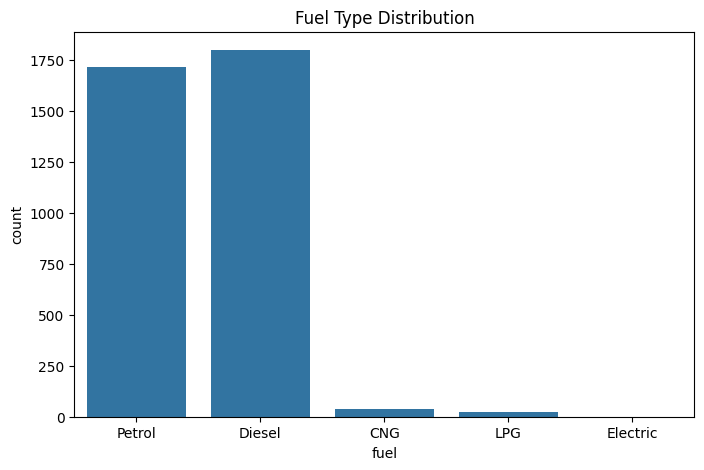

In [26]:
plt.figure(figsize=(8,5))

sns.countplot(data=df_clean,x='fuel')

plt.title("Fuel Type Distribution")

plt.show()

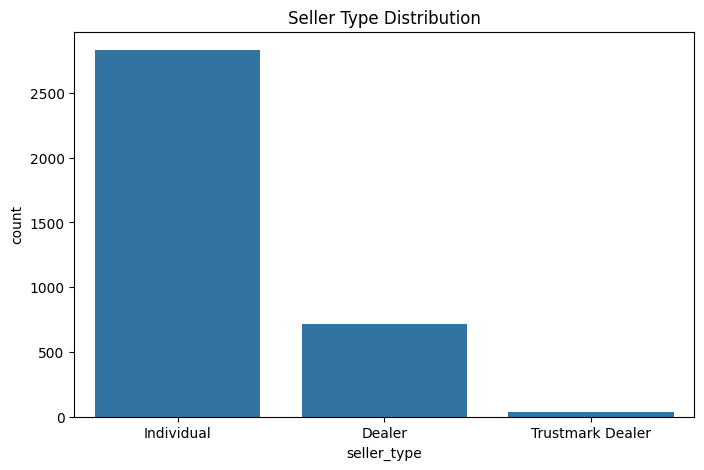

In [27]:
plt.figure(figsize=(8,5))

sns.countplot(data=df_clean,x='seller_type')

plt.title("Seller Type Distribution")

plt.show()

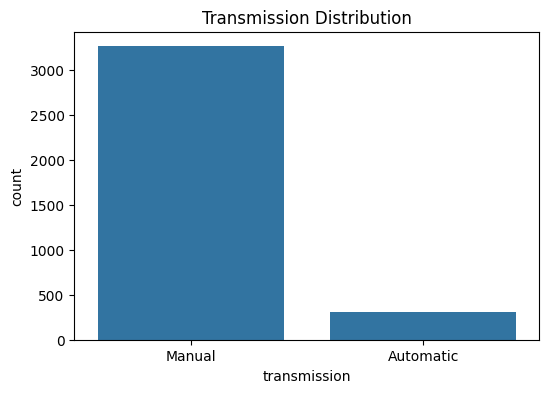

In [28]:
plt.figure(figsize=(6,4))

sns.countplot(data=df_clean,x='transmission')

plt.title("Transmission Distribution")

plt.show()

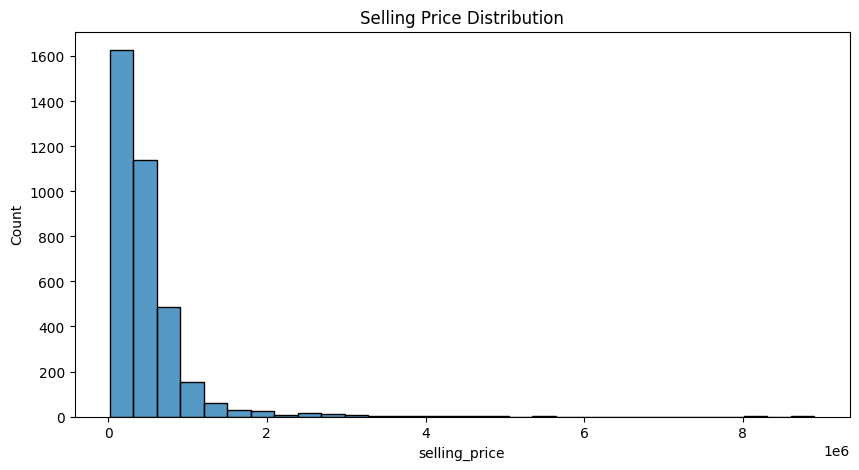

In [29]:
plt.figure(figsize=(10,5))

sns.histplot(df_clean['selling_price'],bins=30)

plt.title("Selling Price Distribution")

plt.show()

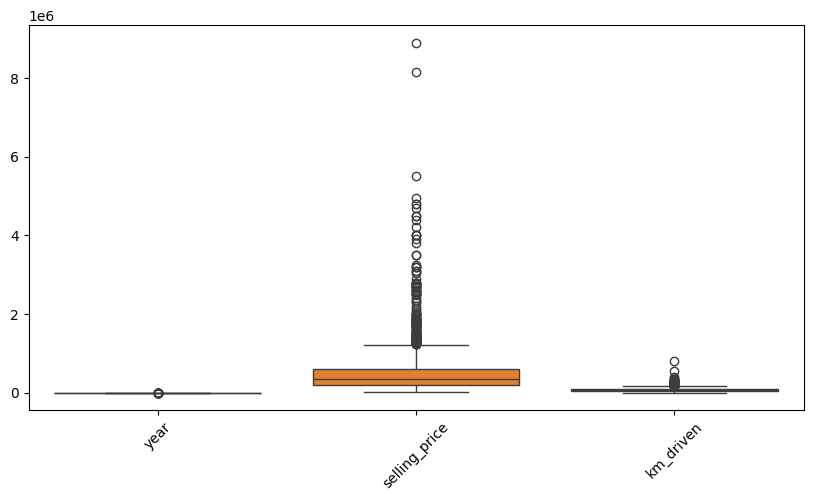

In [30]:
plt.figure(figsize=(10,5))

sns.boxplot(data=numeric_cols)

plt.xticks(rotation=45)

plt.show()

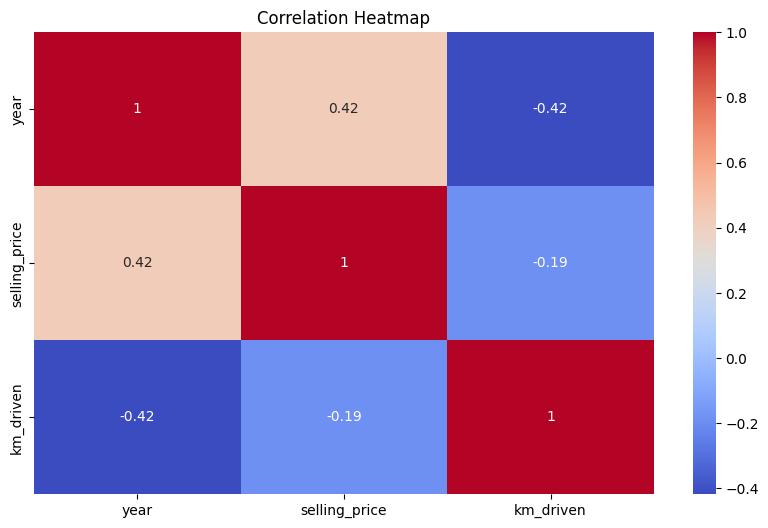

In [31]:
plt.figure(figsize=(10,6))

corr = df_clean.corr(numeric_only=True)

sns.heatmap(corr, annot=True, cmap="coolwarm")

plt.title("Correlation Heatmap")

plt.show()

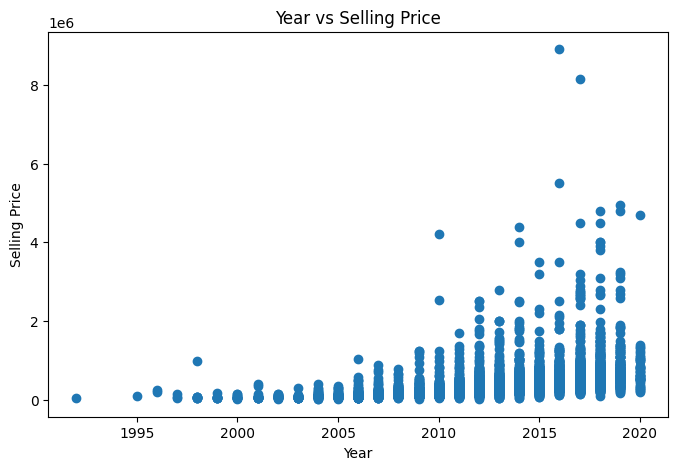

In [32]:
plt.figure(figsize=(8,5))

plt.scatter(df_clean['year'], df_clean['selling_price'])

plt.title("Year vs Selling Price")

plt.xlabel("Year")

plt.ylabel("Selling Price")

plt.show()

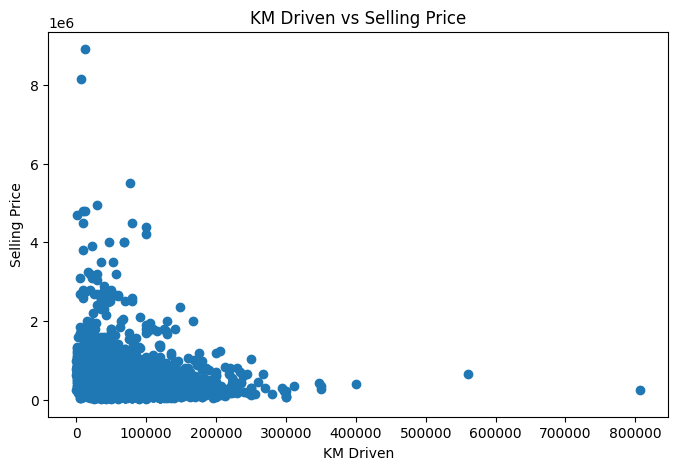

In [33]:
plt.figure(figsize=(8,5))

plt.scatter(df_clean['km_driven'], df_clean['selling_price'])

plt.title("KM Driven vs Selling Price")

plt.xlabel("KM Driven")

plt.ylabel("Selling Price")

plt.show()

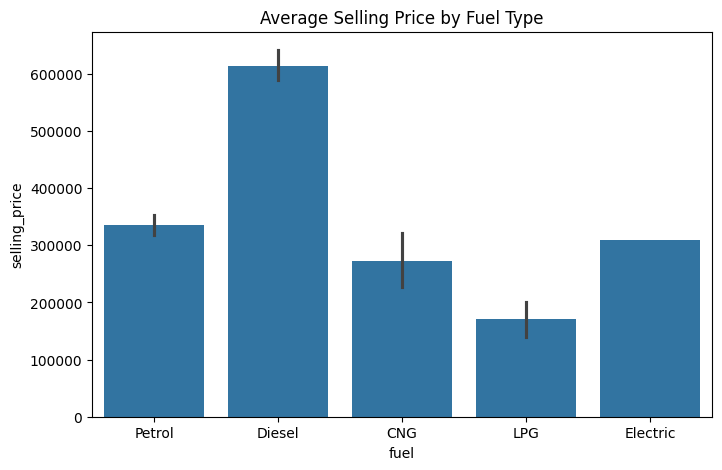

In [34]:
plt.figure(figsize=(8,5))

sns.barplot(data=df_clean,
            x='fuel',
            y='selling_price')

plt.title("Average Selling Price by Fuel Type")

plt.show()

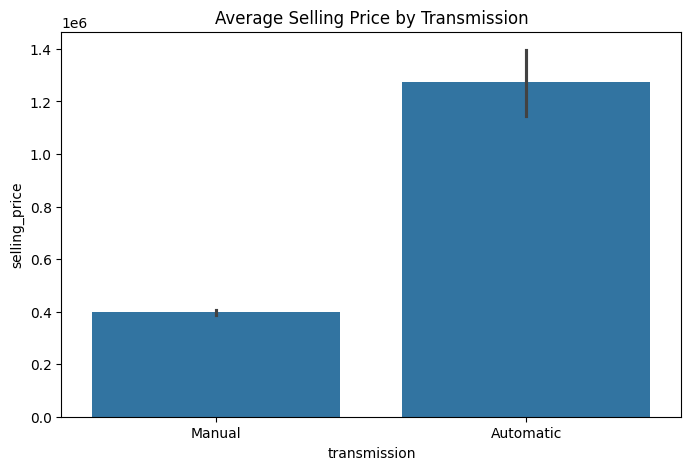

In [35]:
plt.figure(figsize=(8,5))

sns.barplot(data=df_clean,
            x='transmission',
            y='selling_price')

plt.title("Average Selling Price by Transmission")

plt.show()

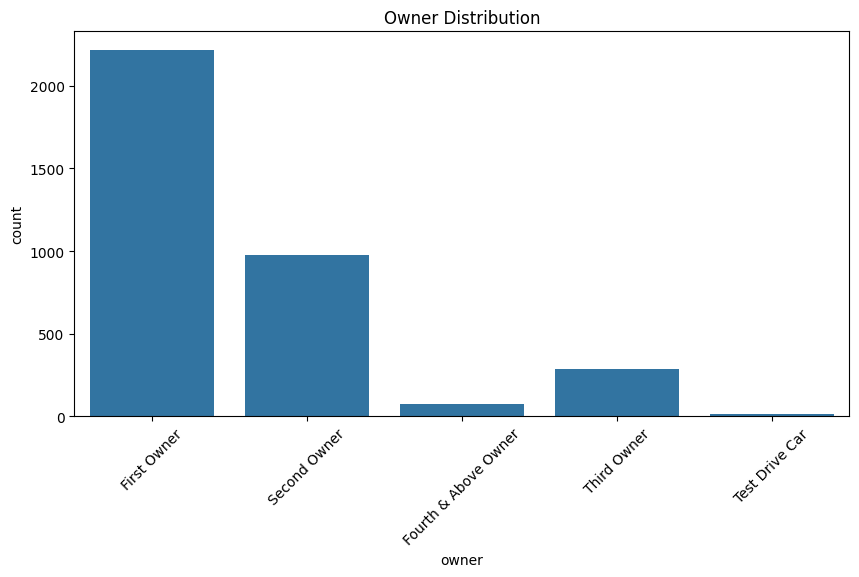

In [36]:
plt.figure(figsize=(10,5))

sns.countplot(data=df_clean,
              x='owner')

plt.xticks(rotation=45)

plt.title("Owner Distribution")

plt.show()

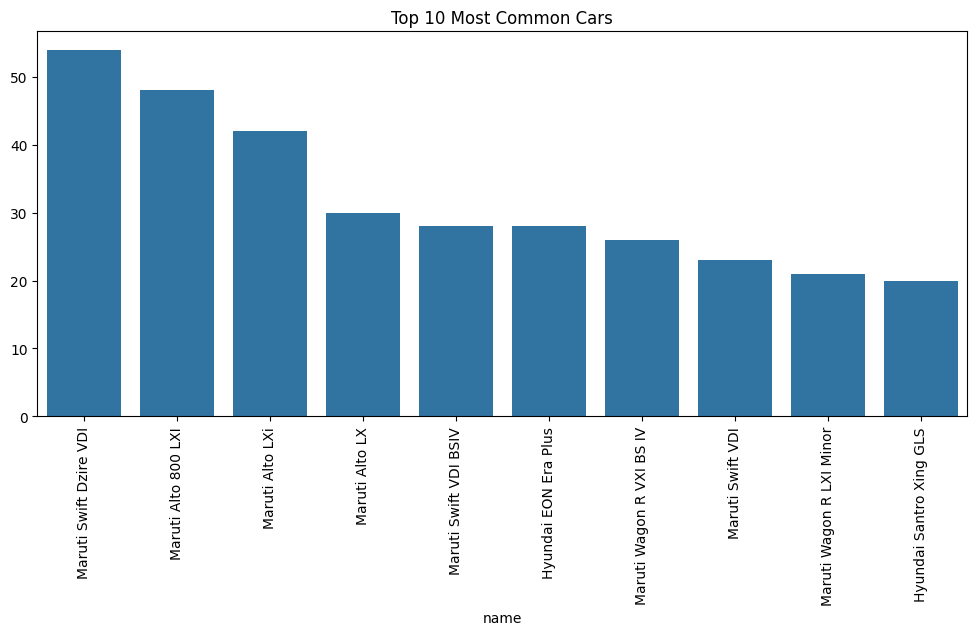

In [37]:
top_brands = df_clean['name'].value_counts().head(10)

plt.figure(figsize=(12,5))

sns.barplot(x=top_brands.index,
            y=top_brands.values)

plt.xticks(rotation=90)

plt.title("Top 10 Most Common Cars")

plt.show()

In [38]:
Q1 = df_clean['selling_price'].quantile(0.25)

Q3 = df_clean['selling_price'].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR

upper_bound = Q3 + 1.5 * IQR

print("Lower Bound =", lower_bound)

print("Upper Bound =", upper_bound)

Lower Bound = -400000.0
Upper Bound = 1200000.0


In [39]:
outliers = df_clean[
    (df_clean['selling_price'] < lower_bound) |
    (df_clean['selling_price'] > upper_bound)
]

print("Number of Outliers:", outliers.shape[0])

Number of Outliers: 170


In [40]:
df_clean = df_clean[
    (df_clean['selling_price'] >= lower_bound) &
    (df_clean['selling_price'] <= upper_bound)
]

In [41]:
df_clean.shape

(3407, 8)

In [42]:
df_clean.to_csv("cleaned_car_data.csv", index=False)

print("Dataset Saved Successfully")

Dataset Saved Successfully


In [ ]:
df_ml = df_clean.copy()

df_ml = pd.get_dummies(
    df_ml,
    columns=['fuel','seller_type','transmission','owner'],
    drop_first=True
)

In [44]:
df_model = df_clean.copy()

df_model['fuel'] = df_model['fuel'].astype('category').cat.codes
df_model['seller_type'] = df_model['seller_type'].astype('category').cat.codes
df_model['transmission'] = df_model['transmission'].astype('category').cat.codes
df_model['owner'] = df_model['owner'].astype('category').cat.codes
df_model['name'] = df_model['name'].astype('category').cat.codes

In [45]:
X = df_model.drop(columns=['selling_price'])

y = df_model['selling_price']

X.head()

,name,year,km_driven,fuel,seller_type,transmission,owner
0,711,2007,70000,4,1,1,0
1,977,2007,50000,4,1,1,0
2,467,2012,100000,1,1,1,0
3,92,2017,46000,4,1,1,0
4,247,2014,141000,1,1,1,2


In [46]:
y.head()

,selling_price
0,60000
1,135000
2,600000
3,250000
4,450000


In [47]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [48]:
print(X_train.shape)
print(X_test.shape)
print(y_train.shape)
print(y_test.shape)

(2725, 7)
(682, 7)
(2725,)
(682,)


In [49]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)

X_test = scaler.transform(X_test)

In [50]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()

model.fit(X_train, y_train)

LinearRegression()

In [51]:
y_pred = model.predict(X_test)

y_pred[:10]

array([636560.51617837, 200130.71024889, 469901.07939088, 316398.38503134,
        98612.867935  , 438739.21567466, 376442.51142118, 408373.37696218,
       473967.51481301, 418124.73472242])

In [52]:
comparison = pd.DataFrame({
    'Actual': y_test,
    'Predicted': y_pred
})

comparison.head(10)

,Actual,Predicted
54,725000,636560.516178
4329,160000,200130.710249
2959,380000,469901.079391
1641,370000,316398.385031
264,100000,98612.867935
1072,540000,438739.215675
725,299000,376442.511421
2119,450000,408373.376962
3433,250000,473967.514813
2460,280000,418124.734722


In [53]:
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score

mae = mean_absolute_error(y_test, y_pred)

mse = mean_squared_error(y_test, y_pred)

r2 = r2_score(y_test, y_pred)

print("MAE =", mae)
print("MSE =", mse)
print("R2 Score =", r2)

MAE = 134077.03648513055
MSE = 30304205242.328133
R2 Score = 0.50389838755583


In [54]:
rmse = np.sqrt(mse)

print("RMSE =", rmse)

RMSE = 174081.03067918724


In [55]:
print("Coefficients:")
print(model.coef_)

Coefficients:
[ -2122.39863391 134042.68038664 -14748.27364772 -77275.9735973
 -12065.310741   -48995.70215669 -10908.75551107]


In [56]:
print("Coefficients:")
print(model.coef_)

Coefficients:
[ -2122.39863391 134042.68038664 -14748.27364772 -77275.9735973
 -12065.310741   -48995.70215669 -10908.75551107]


In [57]:
print("Intercept:")
print(model.intercept_)

Intercept:
392025.7908256858


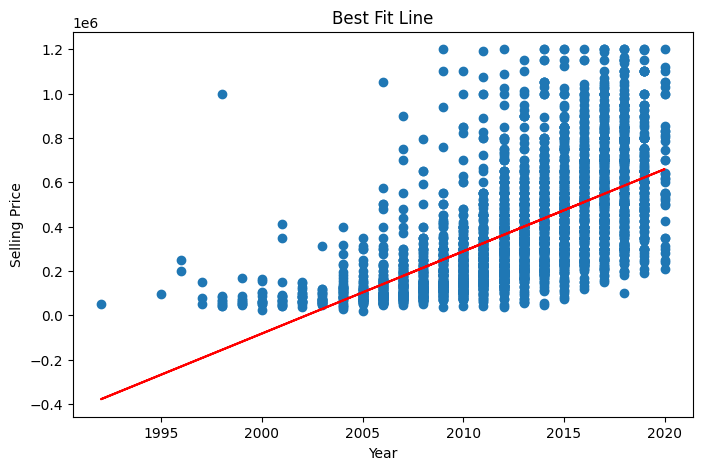

In [58]:
plt.figure(figsize=(8,5))

plt.scatter(df_clean['year'],
            df_clean['selling_price'])

m, c = np.polyfit(
    df_clean['year'],
    df_clean['selling_price'],
    1
)

plt.plot(
    df_clean['year'],
    m * df_clean['year'] + c,
    color='red'
)

plt.xlabel("Year")
plt.ylabel("Selling Price")
plt.title("Best Fit Line")

plt.show()

5 Key Insights (Example)
Petrol and Diesel cars are the most common fuel types.
Selling price generally increases for newer cars.
Cars with higher kilometers driven tend to have lower selling prices.
Automatic transmission cars usually have higher average prices than manual cars.
Some extreme selling prices were identified as outliers and removed using the IQR method.


Conclusion

This project performed Exploratory Data Analysis on the Car Dekho dataset. Data cleaning, missing value checks, duplicate removal, outlier detection, and visualization were performed. Linear Regression was used to predict car selling prices. The analysis helped identify relationships between year, kilometers driven, transmission type, fuel type, and selling price.